# 1. Bibliotheken importieren und Daten laden 💾


In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn import set_config
set_config(transform_output='pandas')
import plotly.graph_objects as go

In [21]:
songs_df = pd.DataFrame()
url = 'https://drive.google.com/file/d/1l9eV0mK87ACovb9ySvvyAwHnFwtmUlZx/view?usp=sharing'
path = 'https://drive.google.com/uc?export=download&id='+url.split('/')[-2]
songs_df = pd.read_csv(path)
songs_df

,Unnamed: 0,name,artist,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,type,duration_ms,time_signature,id,html
0,0,Se Eu Quiser Falar Com Deus ...,Gilberto Gil,0.6580,0.25900,11,-13.141,0,0.0705,0.694,0.000059,0.9750,0.3060,110.376,,256213,4,1n7JnwviZ7zf0LR1tcGFq7,https://open.spotify.com/track/1n7JnwviZ7zf0LR...
1,1,Saudade De Bahia ...,Antônio Carlos Jobim,0.7420,0.39900,2,-12.646,1,0.0346,0.217,0.000002,0.1070,0.6930,125.039,,191867,4,5QGM1U0eCYrQuwSJwTm5Zq,https://open.spotify.com/track/5QGM1U0eCYrQuwS...
2,2,"Canta Canta, Minha Gente ...",Martinho Da Vila,0.8510,0.73000,2,-11.048,1,0.3470,0.453,0.000063,0.1240,0.9050,93.698,,152267,4,0NLIFSZxPzQhCwnkn5PJYs,https://open.spotify.com/track/0NLIFSZxPzQhCwn...
3,3,Mulher Eu Sei ...,Chico César,0.7050,0.05020,4,-18.115,1,0.0471,0.879,0.000041,0.3860,0.5240,106.802,,186227,4,3mXqOdlLE1k67WsAxryPFs,https://open.spotify.com/track/3mXqOdlLE1k67Ws...
4,4,Rosa Morena ...,Kurt Elling,0.6510,0.11900,6,-19.807,1,0.0380,0.916,0.000343,0.1040,0.4020,120.941,,273680,4,7bSzjzjTkWT2CkIPPdp0eA,https://open.spotify.com/track/7bSzjzjTkWT2CkI...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5230,5230,"1812 Festival Overture, Op. 49: 1812 Overture,...",Pyotr Ilyich Tchaikovsky,0.2020,0.06940,3,-23.390,1,0.0473,0.917,0.715000,0.0832,0.0655,87.906,,995000,4,1aEhYlZtypmipA06SDJ4U3,https://open.spotify.com/track/1aEhYlZtypmipA0...
5231,5231,"Winter Fragments pour ensemble instrumental, s...",Tristan Murail,0.1880,0.10100,6,-21.873,1,0.0442,0.855,0.426000,0.0694,0.0355,83.134,,855000,4,1Gfqe7TAKklmuZf6hxsH6h,https://open.spotify.com/track/1Gfqe7TAKklmuZf...
5232,5232,"Schoenberg: 5 Orchestral Pieces, Op. 16: No. 3...",Arnold Schoenberg,0.0596,0.00093,9,-42.959,1,0.0434,0.951,0.969000,0.0772,0.0344,71.573,,238187,3,2XNwnFrdMDpismp0VUZ7cU,https://open.spotify.com/track/2XNwnFrdMDpismp...
5233,5233,"Serenade For Strings In E, Op.22, B. 52: 1. Mo...",Antonín Dvořák,0.1330,0.02080,4,-29.443,1,0.0419,0.883,0.505000,0.1110,0.0591,67.109,,314307,4,7ucDwgMtE3YJtEfTbuRhy0,https://open.spotify.com/track/7ucDwgMtE3YJtEf...


In [22]:
songs_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5235 entries, 0 to 5234
Data columns (total 19 columns):
 #   Column                                                                                                                                                                             Non-Null Count  Dtype  
---  ------                                                                                                                                                                             --------------  -----  
 0   Unnamed: 0                                                                                                                                                                         5235 non-null   int64  
 1   name                                                                                                                                                                               5235 non-null   object 
 2   artist                                                  

# Leerzeichen am Anfang und Ende der Spaltennamen entfernen

In [23]:
songs_df.columns = songs_df.columns.str.strip()

In [24]:
songs_df.columns.to_list()

['Unnamed: 0',
 'name',
 'artist',
 'danceability',
 'energy',
 'key',
 'loudness',
 'mode',
 'speechiness',
 'acousticness',
 'instrumentalness',
 'liveness',
 'valence',
 'tempo',
 'type',
 'duration_ms',
 'time_signature',
 'id',
 'html']

# Die Spalten `Unnamed`, `id`, `type`, `artist` und `html` entfernen, da sie keine numerischen Merkmale für das Clustering enthalten

In [25]:
columus_drop = ['Unnamed: 0','artist','type','id', 'html']
songs_copy_df = songs_df.drop(columns= columus_drop).copy()
songs_copy_df = songs_copy_df.set_index('name')

In [26]:
songs_copy_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5235 entries, Se Eu Quiser Falar Com Deus                                                                                                                                                       to Ravel: Boléro, M. 81                                                                                                                                                           
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   danceability      5235 non-null   float64
 1   energy            5235 non-null   float64
 2   key               5235 non-null   int64  
 3   loudness          5235 non-null   float64
 4   mode              5235 non-null   int64  
 5   speechiness       5235 non-null   float64
 6   acousticness      5235 non-null   float64
 7   instrumentalness  5235 non-null   float64
 8   liveness          5235 non-null   float64
 9   valence           5235 non-nu

# Daten mit StandardScaler skalieren
  Mit StandardScaler skalieren wir die musikalischen Merkmale, sodass sie einen Mittelwert von ungefähr 0 und eine Standardabweichung von 1 haben. Dadurch verhindern wir, dass Merkmale mit größeren Zahlenwerten die Distanzberechnung bei DBSCAN übermäßig beeinflussen.

In [27]:
# StandardScaler initialisieren
my_standardScaler = StandardScaler()

# Musikalische Merkmale standardisieren
scaled_songs_df = my_standardScaler.fit_transform(songs_copy_df)

# Skalierte Daten anzeigen
scaled_songs_df

,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature
name,,,,,,,,,,,,,
Se Eu Quiser Falar Com Deus,0.681116,-1.368556,1.608851,-0.604187,-1.351545,-0.178099,1.134867,-0.694125,5.285610,-0.495488,-0.292147,0.061214,0.230889
Saudade De Bahia,1.066401,-0.882963,-0.911297,-0.525544,0.739894,-0.682409,-0.205206,-0.694278,-0.524470,0.898109,0.221160,-0.413244,0.230889
"Canta Canta, Minha Gente",1.566355,0.265117,-0.911297,-0.271661,0.739894,3.706071,0.457807,-0.694112,-0.410678,1.661526,-0.875994,-0.705236,0.230889
Mulher Eu Sei,0.896692,-2.092782,-0.351264,-1.394432,0.739894,-0.506814,1.654602,-0.694174,1.343056,0.289535,-0.417262,-0.454831,0.230889
Rosa Morena,0.649009,-1.854148,0.208769,-1.663249,0.739894,-0.634647,1.758549,-0.693358,-0.544551,-0.149790,0.077701,0.190008,0.230889
...,...,...,...,...,...,...,...,...,...,...,...,...,...
"1812 Festival Overture, Op. 49: 1812 Overture, Op. 49",-1.410434,-2.026187,-0.631281,-2.232499,0.739894,-0.504004,1.761359,1.234756,-0.683779,-1.361535,-1.078754,5.508689,0.230889
"Winter Fragments pour ensemble instrumental, sons de synthèse et dispositif électronique",-1.474648,-1.916582,0.208769,-1.991485,0.739894,-0.547552,1.587177,0.455047,-0.776151,-1.469566,-1.245808,4.476394,0.230889
"Schoenberg: 5 Orchestral Pieces, Op. 16: No. 3 Farben (Colours)",-2.063584,-2.263676,1.048818,-5.341527,0.739894,-0.558790,1.856877,1.920037,-0.723941,-1.473527,-1.650523,-0.071702,-2.148453


# Epsilon finden (ε) 🔍
  Der Parameter eps bestimmt den maximalen Abstand zwischen zwei Datenpunkten, damit sie als Nachbarn gelten.
- Ist eps zu klein, können zusammengehörige Punkte getrennt werden und einige Punkte als Rauschen gelten.
- Ist eps zu groß, können unterschiedliche Gruppen miteinander verbunden werden.
- Deshalb suchen wir einen geeigneten Wert für eps. Dabei hilft uns der K-Distance Graph


# Epsilon auswählen
  Beim K-Distance Graph berechnen wir für jeden Datenpunkt die Entfernung zu seinem dritten nächsten Nachbarn. Anschließend sortieren wir diese Entfernungen aufsteigend.

Im Diagramm suchen wir nach einem Knickpunkt, an dem die Kurve deutlich steiler wird. Dieser Punkt hilft uns, einen geeigneten Startwert für eps zu finden.


In [28]:
# NearestNeighbors mit drei Nachbarn initialisieren
neighbours = NearestNeighbors(n_neighbors=3)

# Modell an die skalierten Songdaten anpassen
neighbours.fit(scaled_songs_df)

# Abstände und Indizes der Nachbarn berechnen
distances, indices = neighbours.kneighbors(scaled_songs_df)

# Abstände zum dritten Nachbarn auswählen
third_distances = distances[:, 2]

# Abstände aufsteigend sortieren
sorted_distances = sorted(third_distances)

# K-Distance Graph

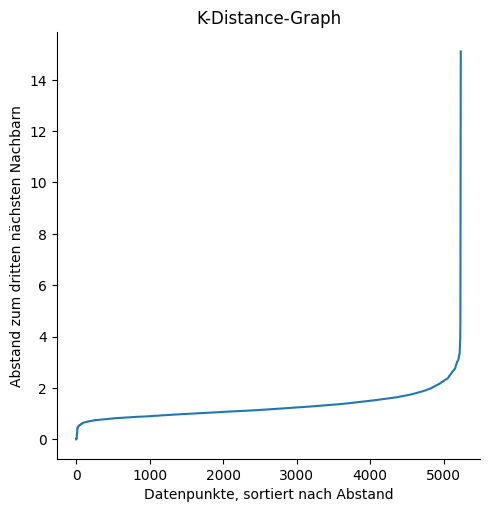

In [29]:
# K-Distance-Graph mit Seaborn darstellen
(
    sns.relplot(
        kind="line",
        x=range(len(sorted_distances)),
        y=sorted_distances
    )
    # Achsenbeschriftungen festlegen
    .set_axis_labels(
        "Datenpunkte, sortiert nach Abstand",
        "Abstand zum dritten nächsten Nachbarn"
    )
    # Titel des Diagramms festlegen
    .set(title="K-Distance-Graph")
);

# DBSCAN anwenden
  

In [30]:
# DBSCAN-Modell mit den gewählten Parametern initialisieren
my_DBSCAN = DBSCAN(eps=2, min_samples=12)

# Modell auf die skalierten Songdaten anwenden
my_DBSCAN.fit(scaled_songs_df)

# Cluster-Zuordnungen den Songdaten hinzufügen
scaled_songs_df['Cluster'] = my_DBSCAN.labels_

# Cluster-Zuordnungen anzeigen
scaled_songs_df['Cluster']

,Cluster
name,
Se Eu Quiser Falar Com Deus,-1
Saudade De Bahia,0
"Canta Canta, Minha Gente",0
Mulher Eu Sei,0
Rosa Morena,0
...,...
"1812 Festival Overture, Op. 49: 1812 Overture, Op. 49",-1
"Winter Fragments pour ensemble instrumental, sons de synthèse et dispositif électronique",-1
"Schoenberg: 5 Orchestral Pieces, Op. 16: No. 3 Farben (Colours)",2


# Anzahl der Songs pro Cluster berechnen

In [31]:
# Anzahl der Songs pro Cluster zählen
songs_count_in_cluster = scaled_songs_df['Cluster'].value_counts().sort_index()

# Verteilung der Songs auf die Cluster anzeigen
songs_count_in_cluster

,count
Cluster,
-1,580
0,2869
1,1547
2,79
3,47
4,21
5,70
6,22


In [32]:

import matplotlib.pyplot as plt

tsne = TSNE(n_components = 2, random_state = 42)

tsne_components = tsne.fit_transform(scaled_songs_df.drop('Cluster', axis=1))



tsne_components['Cluster'] = scaled_songs_df['Cluster']

tsne_components['Cluster'] = tsne_components['Cluster'].astype("string")
tsne_components.loc[tsne_components['Cluster']=='-1', 'Cluster'] = 'Outlier'

g = sns.relplot(data = tsne_components,
                x = 'tsne0',
                y = 'tsne1',
                hue = 'Cluster',
                palette = 'colorblind')


g.set(title = "DBSCAN Clustering Visualisation with t-SNE")


for i, student_name in enumerate(tsne_components.index):

    g.ax.text(tsne_components['tsne0'].iloc[i] + 1,
              tsne_components['tsne1'].iloc[i] + 1,
              student_name,
              fontsize = 9)


plt.show()

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 20132 (\N{CJK UNIFIED IDEOGRAPH-4EA4}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 38911 (\N{CJK UNIFIED IDEOGRAPH-97FF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 26354 (\N{CJK UNIFIED IDEOGRAPH-66F2}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 31532 (\N{CJK UNIFIED IDEOGRAPH-7B2C}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 30058 (\N{CJK UNIFIED IDEOGRAPH-756A}) missing from font(s) DejaVu Sans.
  fig.canvas

ValueError: 
Dance (A$$) Remix                                                                                                                                                                
        ^
ParseException: Expected end of text, found '$'  (at char 8), (line:1, col:9)

<Figure size 597.125x500 with 1 Axes>